In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Predictive Customer Analytics Using ML and Agentic AI")
print("Pandas version:", pd.__version__)


Predictive Customer Analytics Using ML and Agentic AI
Pandas version: 3.1.1


In [2]:
from pathlib import Path

data_folder = Path("../data/raw")

if data_folder.exists():
    csv_files = sorted(data_folder.glob("*.csv"))
    print("Number of CSV files found:", len(csv_files))

    for file in csv_files:
        print(file.name)
else:
    print("Dataset folder not found.")

Number of CSV files found: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [3]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

print("Dataset shape:", customers.shape)

customers.head()

Dataset shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:

# Checking data quality and customer identifiers
print("Missing values in each column:")
print(customers.isnull().sum())

print("\nDuplicate rows:", customers.duplicated().sum())

print("\nUnique customer IDs:", customers["customer_id"].nunique())

print("Unique customers:", customers["customer_unique_id"].nunique())


Missing values in each column:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Duplicate rows: 0

Unique customer IDs: 99441
Unique customers: 96096


In [6]:

# Count how many records belong to each unique customer
customer_counts = customers["customer_unique_id"].value_counts()

print("Total unique customers:", len(customer_counts))

print("\nCustomers with one record:",
      (customer_counts == 1).sum())

print("Customers with multiple records:",
      (customer_counts > 1).sum())

print("\nMaximum records for a single customer:",
      customer_counts.max())

print("\nDistribution of customer record counts:")
print(customer_counts.value_counts().sort_index())


Total unique customers: 96096

Customers with one record: 93099
Customers with multiple records: 2997

Maximum records for a single customer: 17

Distribution of customer record counts:
count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64


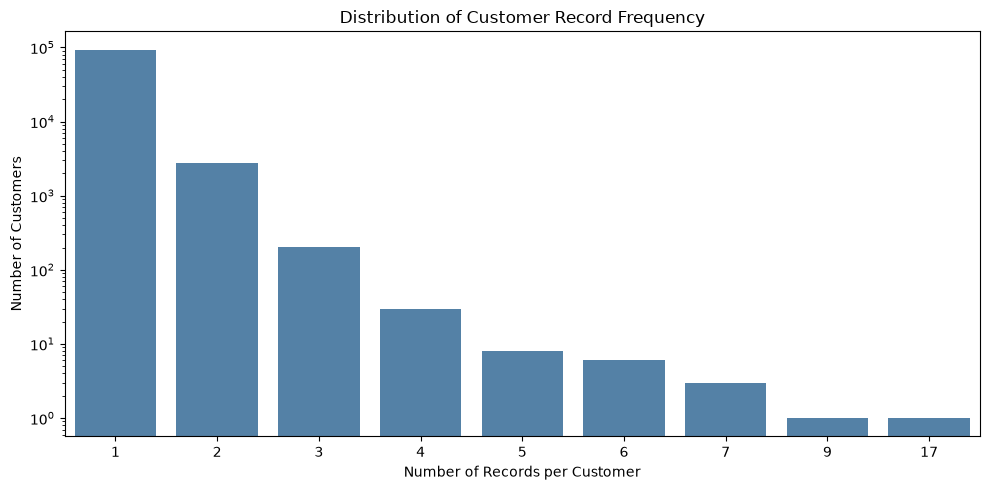

In [7]:

# Visualize customer record frequency
record_distribution = customer_counts.value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=record_distribution.index,
    y=record_distribution.values,
    color="steelblue"
)

plt.title("Distribution of Customer Record Frequency")
plt.xlabel("Number of Records per Customer")
plt.ylabel("Number of Customers")

plt.yscale("log")

plt.tight_layout()
plt.show()


In [8]:

# Load the Olist orders dataset
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

print("Orders dataset shape:", orders.shape)

print("\nColumn names:")
print(orders.columns.tolist())

orders.head()


Orders dataset shape: (99441, 8)

Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [9]:

# Examine order status distribution
print("Order status counts:")
print(orders["order_status"].value_counts())

print("\nOrder status percentages:")
print(
    orders["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Order status percentages:
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


In [10]:

# Convert purchase timestamps into datetime format
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print("Earliest purchase date:",
      orders["order_purchase_timestamp"].min())

print("Latest purchase date:",
      orders["order_purchase_timestamp"].max())

print("\nMissing purchase timestamps:",
      orders["order_purchase_timestamp"].isna().sum())

print("\nOrders by year:")
print(
    orders["order_purchase_timestamp"]
    .dt.year
    .value_counts()
    .sort_index()
)


Earliest purchase date: 2016-09-04 21:15:19
Latest purchase date: 2018-10-17 17:30:18

Missing purchase timestamps: 0

Orders by year:
order_purchase_timestamp
2016      329
2017    45101
2018    54011
Name: count, dtype: int64


Monthly order counts:
order_purchase_timestamp
2016-09-01       4
2016-10-01     324
2016-11-01       0
2016-12-01       1
2017-01-01     800
2017-02-01    1780
2017-03-01    2682
2017-04-01    2404
2017-05-01    3700
2017-06-01    3245
2017-07-01    4026
2017-08-01    4331
2017-09-01    4285
2017-10-01    4631
2017-11-01    7544
2017-12-01    5673
2018-01-01    7269
2018-02-01    6728
2018-03-01    7211
2018-04-01    6939
2018-05-01    6873
2018-06-01    6167
2018-07-01    6292
2018-08-01    6512
2018-09-01      16
2018-10-01       4
Freq: MS, dtype: int64


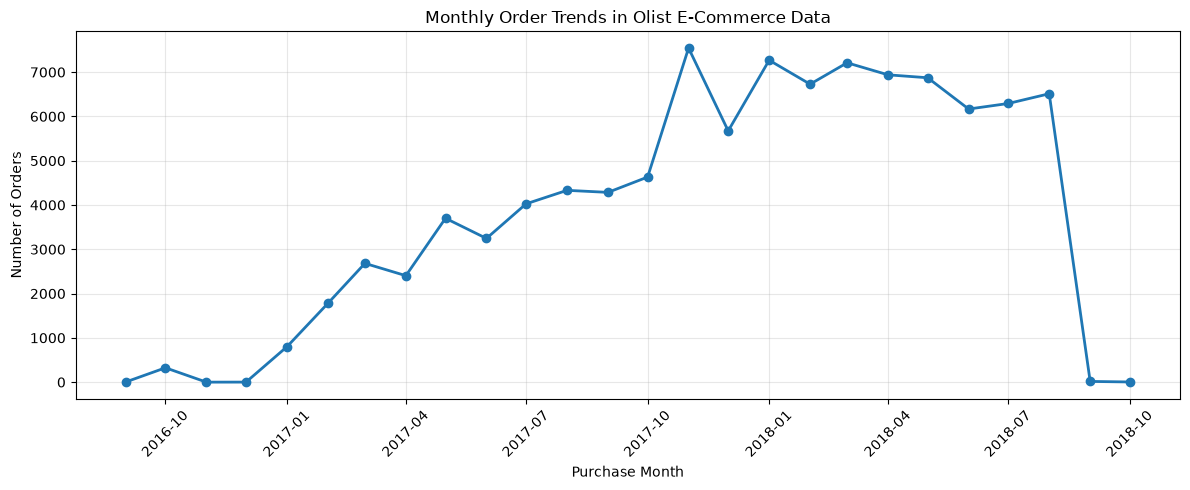

In [11]:

# Analyze monthly order trends
monthly_orders = (
    orders
    .set_index("order_purchase_timestamp")
    .resample("MS")
    .size()
)

print("Monthly order counts:")
print(monthly_orders)

# Plot monthly orders
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders.index,
    monthly_orders.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Order Trends in Olist E-Commerce Data")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

# Combine orders with customer information
customer_orders = orders.merge(
    customers[
        ["customer_id", "customer_unique_id",
         "customer_city", "customer_state"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Combined dataset shape:", customer_orders.shape)

print("\nMissing customer identifiers:")
print(customer_orders["customer_unique_id"].isna().sum())

print("\nUnique customers:")
print(customer_orders["customer_unique_id"].nunique())

print("\nUnique orders:")
print(customer_orders["order_id"].nunique())

customer_orders.head()


Combined dataset shape: (99441, 11)

Missing customer identifiers:
0

Unique customers:
96096

Unique orders:
99441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP


In [13]:

# Analyze repeat purchasing behavior
# Count orders for each unique customer
customer_order_counts = (
    customer_orders
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

# Identify one-time and repeat customers
one_time_customers = (customer_order_counts == 1).sum()
repeat_customers = (customer_order_counts > 1).sum()
total_customers = len(customer_order_counts)
repeat_percentage = (
    repeat_customers / total_customers
) * 100

print("Total unique customers:", total_customers)
print("One-time customers:", one_time_customers)

print("Repeat customers:", repeat_customers)
print("Repeat customer percentage:",
      round(repeat_percentage, 2), "%")

print("\nMaximum orders by one customer:",
      customer_order_counts.max())


Total unique customers: 96096
One-time customers: 93099
Repeat customers: 2997
Repeat customer percentage: 3.12 %

Maximum orders by one customer: 17


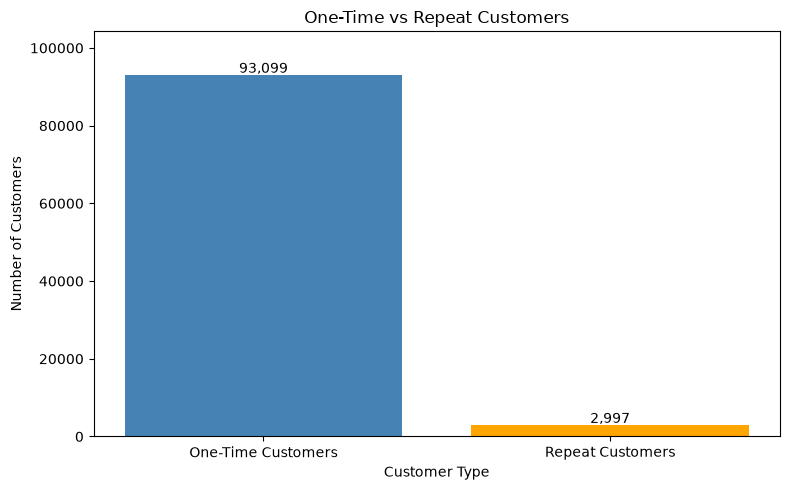

In [14]:

# Visualize one-time and repeat customers
customer_types = ["One-Time Customers", "Repeat Customers"]

customer_values = [one_time_customers, repeat_customers]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    customer_types,
    customer_values,
    color=["steelblue", "orange"]
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 500,
        f"{int(height):,}",
        ha="center"
    )

plt.ylim(0, max(customer_values) * 1.12)
plt.tight_layout()
plt.show()


In [15]:

# Calculate customer purchase recency
# Use a reference date after the latest recorded purchase
reference_date = (
    customer_orders["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Find each customer's most recent purchase
last_purchase_dates = (
    customer_orders
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .max()
)

# Calculate recency in days
customer_recency = (
    reference_date - last_purchase_dates
).dt.days

print("Reference date:", reference_date)

print("\nCustomer recency summary:")
print(customer_recency.describe())

print("\nSample customer recency values:")
print(customer_recency.head())


Reference date: 2018-10-18 17:30:18

Customer recency summary:
count    96096.000000
mean       288.735691
std        153.414676
min          1.000000
25%        164.000000
50%        269.000000
75%        398.000000
max        773.000000
Name: order_purchase_timestamp, dtype: float64

Sample customer recency values:
customer_unique_id
0000366f3b9a7992bf8c76cfdf3221e2    161
0000b849f77a49e4a4ce2b2a4ca5be3f    164
0000f46a3911fa3c0805444483337064    586
0000f6ccb0745a6a4b88665a16c9f078    370
0004aac84e0df4da2b147fca70cf8255    337
Name: order_purchase_timestamp, dtype: int64


In [16]:

# Combine customer purchase frequency and recency
customer_rf = pd.DataFrame({
    "frequency": customer_order_counts,
    "recency": customer_recency
})

print("Customer Frequency and Recency dataset:")
print(customer_rf.head())

print("\nSummary statistics:")
print(customer_rf.describe())

print("\nMissing values:")
print(customer_rf.isnull().sum())


Customer Frequency and Recency dataset:
                                  frequency  recency
customer_unique_id                                  
0000366f3b9a7992bf8c76cfdf3221e2          1      161
0000b849f77a49e4a4ce2b2a4ca5be3f          1      164
0000f46a3911fa3c0805444483337064          1      586
0000f6ccb0745a6a4b88665a16c9f078          1      370
0004aac84e0df4da2b147fca70cf8255          1      337

Summary statistics:
          frequency       recency
count  96096.000000  96096.000000
mean       1.034809    288.735691
std        0.214384    153.414676
min        1.000000      1.000000
25%        1.000000    164.000000
50%        1.000000    269.000000
75%        1.000000    398.000000
max       17.000000    773.000000

Missing values:
frequency    0
recency      0
dtype: int64


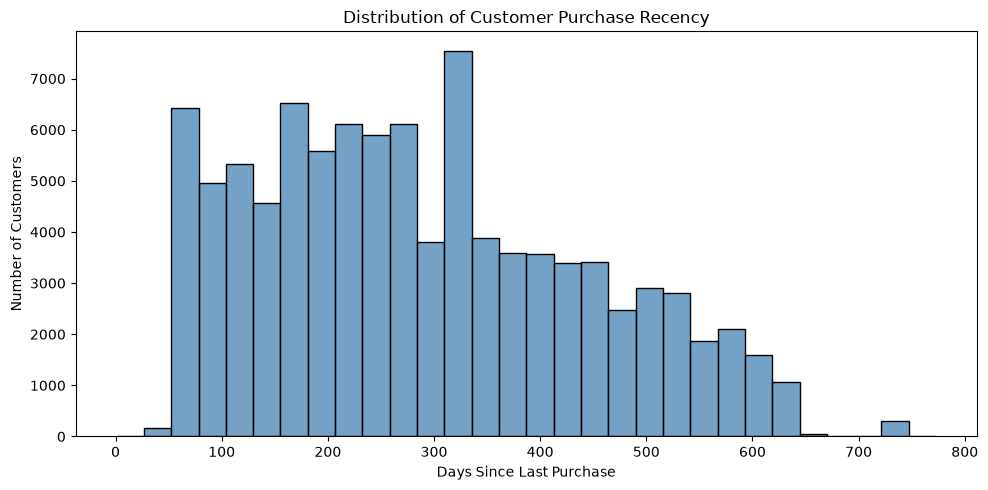

In [17]:

# Visualize customer purchase recency

plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_rf,
    x="recency",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Customer Purchase Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


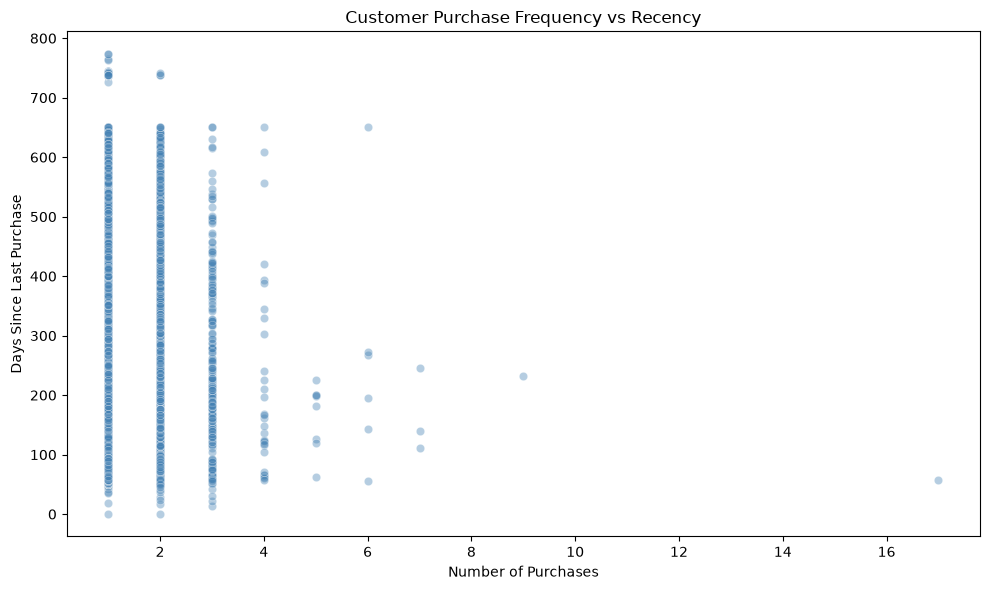

In [19]:

# Explore the relationship between purchase frequency and recency

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_rf,
    x="frequency",
    y="recency",
    alpha=0.4,
    color="steelblue"
)

plt.title("Customer Purchase Frequency vs Recency")
plt.xlabel("Number of Purchases")
plt.ylabel("Days Since Last Purchase")

plt.tight_layout()
plt.show()


In [20]:

# Segment customers using purchase frequency and recency

def assign_customer_segment(row):
    if row["frequency"] >= 2 and row["recency"] <= 180:
        return "Active Repeat"

    elif row["frequency"] >= 2 and row["recency"] > 180:
        return "At-Risk Repeat"

    elif row["frequency"] == 1 and row["recency"] <= 180:
        return "Recent One-Time"

    else:
        return "Inactive One-Time"


customer_rf["segment"] = customer_rf.apply(
    assign_customer_segment,
    axis=1
)

print("Customer segment distribution:")
print(customer_rf["segment"].value_counts())

print("\nCustomer segment percentages:")
print(
    customer_rf["segment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

customer_rf.head()


Customer segment distribution:
segment
Inactive One-Time    66327
Recent One-Time      26772
At-Risk Repeat        2025
Active Repeat          972
Name: count, dtype: int64

Customer segment percentages:
segment
Inactive One-Time    69.02
Recent One-Time      27.86
At-Risk Repeat        2.11
Active Repeat         1.01
Name: proportion, dtype: float64


,frequency,recency,segment
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,1,161,Recent One-Time
0000b849f77a49e4a4ce2b2a4ca5be3f,1,164,Recent One-Time
0000f46a3911fa3c0805444483337064,1,586,Inactive One-Time
0000f6ccb0745a6a4b88665a16c9f078,1,370,Inactive One-Time
0004aac84e0df4da2b147fca70cf8255,1,337,Inactive One-Time


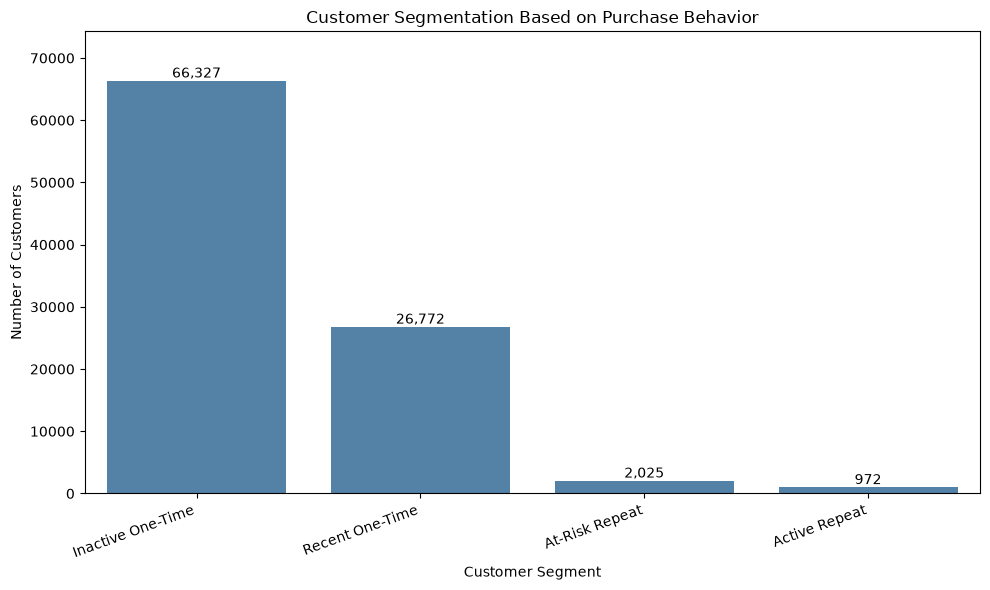

In [21]:

# Visualize customer segment distribution

segment_counts = customer_rf["segment"].value_counts()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values,
    color="steelblue"
)

plt.title("Customer Segmentation Based on Purchase Behavior")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20, ha="right")

# Display customer counts above each bar
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.ylim(0, segment_counts.max() * 1.12)
plt.tight_layout()
plt.show()


In [22]:

# Analyze average purchase recency by customer segment

segment_summary = (
    customer_rf.groupby("segment")
    .agg(
        total_customers=("frequency", "count"),
        average_frequency=("frequency", "mean"),
        average_recency=("recency", "mean"),
        median_recency=("recency", "median")
    )
    .round(2)
    .sort_values("total_customers", ascending=False)
)

print("Customer segment summary:")
display(segment_summary)


Customer segment summary:


,total_customers,average_frequency,average_recency,median_recency
segment,,,,
Inactive One-Time,66327,1.00,359.40,330.0
Recent One-Time,26772,1.00,115.85,115.0
At-Risk Repeat,2025,2.10,343.81,324.0
Active Repeat,972,2.15,113.78,114.0


In [23]:

# Save customer segmentation results

from pathlib import Path

output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "customer_segments.csv"

customer_rf.reset_index().to_csv(
    output_file,
    index=False
)

print("Customer segmentation dataset saved successfully!")
print("File location:", output_file)

print("\nDataset shape:")
print(customer_rf.shape)

print("\nDataset columns:")
print(customer_rf.columns.tolist())


Customer segmentation dataset saved successfully!
File location: ../data/processed/customer_segments.csv

Dataset shape:
(96096, 3)

Dataset columns:
['frequency', 'recency', 'segment']
